# AI 이미지 탐지 모델 평가
누적 학습 모델, 개별 데이터셋 모델, 외부 모델을 동일한 테스트셋으로 비교 평가합니다.

## 0. 환경 설정

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p ~/.kaggle
!cp "/content/drive/MyDrive/kaggle.json" ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Mounted at /content/drive


In [2]:
import os
import json
import shutil
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from tensorflow.keras.models import load_model

IMG_SIZE = 128
SAVE_DIR = "/content/drive/MyDrive/model_results"
os.makedirs(SAVE_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. 데이터셋 준비

### 1-1. 학습 데이터 다운로드 및 전처리

In [3]:
import pandas as pd

def make_dirs(base):
    for split in ["train", "val"]:
        for cls in ["real", "ai"]:
            os.makedirs(os.path.join(base, split, cls), exist_ok=True)

def split_and_move(src, dst, label, split_ratio=0.8):
    images = []
    for root, _, files in os.walk(src):
        for f in files:
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
                images.append(os.path.join(root, f))
    random.seed(42)
    random.shuffle(images)
    split_idx = int(len(images) * split_ratio)
    train_imgs = images[:split_idx]
    val_imgs = images[split_idx:]
    for img_path in train_imgs:
        shutil.copy(img_path, os.path.join(dst, "train", label, os.path.basename(img_path)))
    for img_path in val_imgs:
        shutil.copy(img_path, os.path.join(dst, "val", label, os.path.basename(img_path)))
    print(f"{label}: train={len(train_imgs)}, val={len(val_imgs)}")

def convert_dataset(base_dir, ai_paths, real_paths, out_dir):
    print("="*60)
    print("Processing:", base_dir)
    print("="*60)
    make_dirs(out_dir)
    for p in ai_paths:
        split_and_move(p, out_dir, "ai")
    for p in real_paths:
        split_and_move(p, out_dir, "real")

def split_and_move_from_csv(df, base_dir, out_dir, label_name, split_ratio=0.8):
    rows = df.to_dict("records")
    random.seed(42)
    random.shuffle(rows)
    split_idx = int(len(rows) * split_ratio)
    for row in rows[:split_idx]:
        src_path = os.path.join(base_dir, row["file_name"])
        dst_path = os.path.join(out_dir, "train", label_name, os.path.basename(row["file_name"]))
        if os.path.exists(src_path):
            shutil.copy2(src_path, dst_path)
    for row in rows[split_idx:]:
        src_path = os.path.join(base_dir, row["file_name"])
        dst_path = os.path.join(out_dir, "val", label_name, os.path.basename(row["file_name"]))
        if os.path.exists(src_path):
            shutil.copy2(src_path, dst_path)
    print(f"{label_name}: train={int(len(rows)*split_ratio)}, val={len(rows)-int(len(rows)*split_ratio)}")

def convert_dataset_csv(base_dir, csv_path, out_dir):
    print("="*60)
    print("Processing:", base_dir)
    print("="*60)
    make_dirs(out_dir)
    df = pd.read_csv(csv_path)
    real_df = df[df["label"] == 0]
    ai_df = df[df["label"] == 1]
    print(f"REAL: {len(real_df)}, AI: {len(ai_df)}")
    split_and_move_from_csv(real_df, base_dir, out_dir, "real")
    split_and_move_from_csv(ai_df, base_dir, out_dir, "ai")

In [4]:
# Phase 1 - CIFAKE
!kaggle datasets download -d birdy654/cifake-real-and-ai-generated-synthetic-images
!unzip -o -q cifake-real-and-ai-generated-synthetic-images.zip -d 1_CIFAKE
!rm cifake-real-and-ai-generated-synthetic-images.zip

convert_dataset(
    "/content/1_CIFAKE",
    ai_paths=["/content/1_CIFAKE/train/FAKE", "/content/1_CIFAKE/test/FAKE"],
    real_paths=["/content/1_CIFAKE/train/REAL", "/content/1_CIFAKE/test/REAL"],
    out_dir="/content/clean/Phase1_CIFAKE"
)

Dataset URL: https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images
License(s): other
100% 105M/105M [00:00<00:00, 182MB/s]

Processing: /content/1_CIFAKE
ai: train=40000, val=10000
ai: train=8000, val=2000
real: train=40000, val=10000
real: train=8000, val=2000


In [5]:
# Phase 3 - AI vs Real Images (SDXL 기반)
!kaggle datasets download -d rhythmghai/ai-vs-real-images-dataset
!unzip -o -q ai-vs-real-images-dataset.zip -d 3_AI_vs_Real
!rm ai-vs-real-images-dataset.zip

convert_dataset(
    "/content/3_AI_vs_Real",
    ai_paths=["/content/3_AI_vs_Real/Ai_generated_dataset"],
    real_paths=["/content/3_AI_vs_Real/real_dataset"],
    out_dir="/content/clean/Phase3_AI_REAL"
)

Dataset URL: https://www.kaggle.com/datasets/rhythmghai/ai-vs-real-images-dataset
License(s): CC-BY-NC-SA-4.0
100% 237M/237M [00:01<00:00, 131MB/s]

Processing: /content/3_AI_vs_Real
ai: train=200, val=50
real: train=596, val=149


In [6]:
# Phase 4 - AI vs Human Generated
!kaggle datasets download -d alessandrasala79/ai-vs-human-generated-dataset
!unzip -o -q ai-vs-human-generated-dataset.zip -d 4_AI_vs_Human
!rm ai-vs-human-generated-dataset.zip

convert_dataset_csv(
    base_dir="/content/4_AI_vs_Human",
    csv_path="/content/4_AI_vs_Human/train.csv",
    out_dir="/content/clean/Phase4_AI_REAL"
)

Dataset URL: https://www.kaggle.com/datasets/alessandrasala79/ai-vs-human-generated-dataset
License(s): apache-2.0
100% 9.76G/9.76G [01:46<00:00, 98.3MB/s]

Processing: /content/4_AI_vs_Human
REAL: 39975, AI: 39975
real: train=31980, val=7995
ai: train=31980, val=7995


In [15]:
!find /content/4_AI_vs_Human -maxdepth 3 -type d | head -100

/content/4_AI_vs_Human
/content/4_AI_vs_Human/test_data_v2
/content/4_AI_vs_Human/train_data


In [16]:
!find /content/5_Real_vs_AI_Faces -maxdepth 3 -type d | head -100

/content/5_Real_vs_AI_Faces
/content/5_Real_vs_AI_Faces/data_source
/content/5_Real_vs_AI_Faces/data_source/data_source
/content/5_Real_vs_AI_Faces/data_source/data_source/ffhq
/content/5_Real_vs_AI_Faces/data_source/data_source/fake
/content/5_Real_vs_AI_Faces/dataset
/content/5_Real_vs_AI_Faces/dataset/dataset
/content/5_Real_vs_AI_Faces/dataset/dataset/train
/content/5_Real_vs_AI_Faces/dataset/dataset/test
/content/5_Real_vs_AI_Faces/dataset/dataset/validate


In [17]:
# Phase 5 - Real vs AI Generated Faces
!kaggle datasets download -d philosopher0808/real-vs-ai-generated-faces-dataset
!unzip -o -q real-vs-ai-generated-faces-dataset.zip -d 5_Real_vs_AI_Faces
!rm real-vs-ai-generated-faces-dataset.zip

# Phase 5 데이터 구조에 맞게 경로 수정 필요
convert_dataset(
    "/content/5_Real_vs_AI_Faces",
    ai_paths=[
        "/content/5_Real_vs_AI_Faces/data_source/data_source/fake/stable_diffusion",
        "/content/5_Real_vs_AI_Faces/data_source/data_source/fake/sfhq/pt1",
        "/content/5_Real_vs_AI_Faces/data_source/data_source/fake/sfhq/pt2",
        "/content/5_Real_vs_AI_Faces/data_source/data_source/fake/sfhq/pt3",
        "/content/5_Real_vs_AI_Faces/data_source/data_source/fake/sfhq/pt4",
        "/content/5_Real_vs_AI_Faces/data_source/data_source/fake/faceswap",
        "/content/5_Real_vs_AI_Faces/data_source/data_source/fake/thispersondoesnotexist"
    ],
    real_paths=[
        "/content/5_Real_vs_AI_Faces/data_source/data_source/ffhq"
    ],
    out_dir="/content/clean/Phase5_AI_REAL"
)

Dataset URL: https://www.kaggle.com/datasets/philosopher0808/real-vs-ai-generated-faces-dataset
License(s): MIT
100% 7.19G/7.19G [01:11<00:00, 107MB/s]

Processing: /content/5_Real_vs_AI_Faces
ai: train=824, val=207
ai: train=4000, val=1000
ai: train=4000, val=1000
ai: train=4000, val=1000
ai: train=4000, val=1000
ai: train=7543, val=1886
ai: train=16399, val=4100
real: train=56000, val=14000


### 1-2. 테스트 데이터 준비 (SynthBuster)

In [8]:
import kagglehub

real_path = kagglehub.dataset_download("duyminhle/real-image-dataset")
shutil.copytree(real_path, "/content/test_real", dirs_exist_ok=True)

fake_path = kagglehub.dataset_download("devpatel484/synthbuster-32")
shutil.copytree(fake_path, "/content/test_fake", dirs_exist_ok=True)

for label, path in [("REAL", "/content/test_real"), ("FAKE", "/content/test_fake")]:
    print(f"\n--- {label} ---")
    for root, dirs, files in os.walk(path):
        imgs = [f for f in files if f.lower().endswith(('.jpg','.png','.jpeg','.webp'))]
        if imgs:
            print(f"{root}: {len(imgs)}장")

Using Colab cache for faster access to the 'real-image-dataset' dataset.
Using Colab cache for faster access to the 'synthbuster-32' dataset.

--- REAL ---
/content/test_real/images: 9000장

--- FAKE ---
/content/test_fake/resized_data_Synthbuster/Synthbuster_Dataset/dalle2: 1000장
/content/test_fake/resized_data_Synthbuster/Synthbuster_Dataset/stable-diffusion-2: 1000장
/content/test_fake/resized_data_Synthbuster/Synthbuster_Dataset/stable-diffusion-1-3: 1000장
/content/test_fake/resized_data_Synthbuster/Synthbuster_Dataset/glide: 1000장
/content/test_fake/resized_data_Synthbuster/Synthbuster_Dataset/stable-diffusion-1-4: 1000장
/content/test_fake/resized_data_Synthbuster/Synthbuster_Dataset/stable-diffusion-xl: 1000장
/content/test_fake/resized_data_Synthbuster/Synthbuster_Dataset/dalle3: 1000장
/content/test_fake/resized_data_Synthbuster/Synthbuster_Dataset/firefly: 1000장
/content/test_fake/resized_data_Synthbuster/Synthbuster_Dataset/midjourney-v5: 1000장


## 2. 모델 및 데이터 로더 정의

In [9]:
def build_cnn(img_size=128):
    model = tf.keras.Sequential([
        tf.keras.layers.Rescaling(1./255, input_shape=(img_size, img_size, 3)),
        tf.keras.layers.Conv2D(32, 3, activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(64, 3, activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(128, 3, activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(2, activation='softmax')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-4),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

def load_data(path, batch_size=32):
    AUTOTUNE = tf.data.AUTOTUNE
    train_ds = tf.keras.preprocessing.image_dataset_from_directory(
        path + "/train",
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=batch_size,
        label_mode='int'
    ).prefetch(AUTOTUNE)
    val_ds = tf.keras.preprocessing.image_dataset_from_directory(
        path + "/val",
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=batch_size,
        label_mode='int'
    ).prefetch(AUTOTUNE)
    return train_ds, val_ds

def load_test_ds(real_dir, fake_dir, image_size=(128, 128), batch_size=32):
    real_paths = list(Path(real_dir).glob("*.jpg")) + \
                 list(Path(real_dir).glob("*.png")) + \
                 list(Path(real_dir).glob("*.jpeg"))
    fake_paths = list(Path(fake_dir).glob("**/*.jpg")) + \
                 list(Path(fake_dir).glob("**/*.png")) + \
                 list(Path(fake_dir).glob("**/*.jpeg")) + \
                 list(Path(fake_dir).glob("**/*.webp"))
    print(f"Real: {len(real_paths)}장, Fake: {len(fake_paths)}장")
    all_paths = [str(p) for p in fake_paths + real_paths]
    all_labels = [0] * len(fake_paths) + [1] * len(real_paths)  # ai=0, real=1
    def preprocess(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_image(img, channels=3, expand_animations=False)
        img = tf.image.resize(img, image_size)
        img = tf.cast(img, tf.float32)
        return img, label
    ds = tf.data.Dataset.from_tensor_slices((all_paths, all_labels))
    ds = ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

# 테스트셋 로드 (모델 내부에 Rescaling 있으므로 /255 없음)
test_ds = load_test_ds(
    real_dir="/content/test_real/images",
    fake_dir="/content/test_fake/resized_data_Synthbuster/Synthbuster_Dataset"
)

Real: 9000장, Fake: 9000장


In [40]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np
import pandas as pd
import tensorflow as tf

def evaluate_model(model, test_ds, positive_label=0):
    y_true = np.concatenate([y.numpy() for _, y in test_ds])

    y_prob = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label=positive_label),
        "recall": recall_score(y_true, y_pred, pos_label=positive_label),
        "f1": f1_score(y_true, y_pred, pos_label=positive_label)
    }

## 3. 개별 데이터셋 모델 학습

In [3]:
EPOCHS = 20

def train_and_save(phase_name, phase_path):
    print(f"\n{'='*50}")
    print(f"  {phase_name} 학습 시작")
    print(f"{'='*50}")
    train_ds, val_ds = load_data(phase_path)
    model = build_cnn()
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)
    test_loss, test_acc = model.evaluate(test_ds)
    model.save(f"{SAVE_DIR}/model_{phase_name}.h5")
    results = {
        "dataset": phase_name,
        "train_acc": history.history['accuracy'],
        "val_acc": history.history['val_accuracy'],
        "train_loss": history.history['loss'],
        "val_loss": history.history['val_loss'],
        "test_acc": float(test_acc),
        "test_loss": float(test_loss)
    }
    with open(f"{SAVE_DIR}/results_{phase_name}.json", "w") as f:
        json.dump(results, f, indent=2)
    print(f"  저장 완료 → val_acc: {max(history.history['val_accuracy']):.4f} / test_acc: {test_acc:.4f}")
    return history, test_acc

In [11]:
history_p1, test_acc_p1 = train_and_save("phase1", "/content/clean/Phase1_CIFAKE")


  phase1 학습 시작
Found 89637 files belonging to 2 classes.
Found 23618 files belonging to 2 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
2802/2802 ━━━━━━━━━━━━━━━━━━━━ 77s 25ms/step - accuracy: 0.8366 - loss: 0.3687 - val_accuracy: 0.8881 - val_loss: 0.2719
Epoch 2/20
2802/2802 ━━━━━━━━━━━━━━━━━━━━ 59s 21ms/step - accuracy: 0.8959 - loss: 0.2591 - val_accuracy: 0.9076 - val_loss: 0.2293
Epoch 3/20
2802/2802 ━━━━━━━━━━━━━━━━━━━━ 59s 21ms/step - accuracy: 0.9151 - loss: 0.2179 - val_accuracy: 0.9246 - val_loss: 0.1946
Epoch 4/20
2802/2802 ━━━━━━━━━━━━━━━━━━━━ 60s 21ms/step - accuracy: 0.9256 - loss: 0.1920 - val_accuracy: 0.9342 - val_loss: 0.1694
Epoch 5/20
2802/2802 ━━━━━━━━━━━━━━━━━━━━ 59s 21ms/step - accuracy: 0.9338 - loss: 0.1726 - val_accuracy: 0.9405 - val_loss: 0.1539
Epoch 6/20
2802/2802 ━━━━━━━━━━━━━━━━━━━━ 58s 21ms/step - accuracy: 0.9405 - loss: 0.1568 - val_accuracy: 0.9444 - val_loss: 0.1473
Epoch 7/20
2802/2802 ━━━━━━━━━━━━━━━━━━━━ 62s 22ms/step - accuracy: 0.9458 - loss: 0.1431 - val_accuracy: 0.9386 - val_loss: 0.1609
Epoch 8/20
2802/2802 ━━━━━━━━━━━━━━━━━━━━ 62s 22ms/step - accuracy: 0.9500 -

  저장 완료 → val_acc: 0.9576 / test_acc: 0.2019


In [12]:
history_p3, test_acc_p3 = train_and_save("phase3", "/content/clean/Phase3_AI_REAL")


  phase3 학습 시작
Found 646 files belonging to 2 classes.
Found 180 files belonging to 2 classes.
Epoch 1/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 18s 652ms/step - accuracy: 0.9009 - loss: 0.3605 - val_accuracy: 0.8278 - val_loss: 0.5401
Epoch 2/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 15s 502ms/step - accuracy: 0.9226 - loss: 0.3019 - val_accuracy: 0.8278 - val_loss: 0.5175
Epoch 3/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 11s 530ms/step - accuracy: 0.9226 - loss: 0.2942 - val_accuracy: 0.8278 - val_loss: 0.4441
Epoch 4/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 480ms/step - accuracy: 0.9226 - loss: 0.2592 - val_accuracy: 0.8278 - val_loss: 0.4115
Epoch 5/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 416ms/step - accuracy: 0.9226 - loss: 0.2416 - val_accuracy: 0.8278 - val_loss: 0.4105
Epoch 6/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 12s 499ms/step - accuracy: 0.9241 - loss: 0.2175 - val_accuracy: 0.8500 - val_loss: 0.3825
Epoch 7/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 19s 450ms/step - accuracy: 0.9303 - loss: 0.2213 - val_accuracy: 0.8389 - val_loss: 0.3807
Ep

  저장 완료 → val_acc: 0.8889 / test_acc: 0.4824


In [13]:
history_p4, test_acc_p4 = train_and_save("phase4", "/content/clean/Phase4_AI_REAL")


  phase4 학습 시작
Found 63960 files belonging to 2 classes.
Found 15990 files belonging to 2 classes.
Epoch 1/20
1999/1999 ━━━━━━━━━━━━━━━━━━━━ 193s 95ms/step - accuracy: 0.8708 - loss: 0.3138 - val_accuracy: 0.9173 - val_loss: 0.2247
Epoch 2/20
1999/1999 ━━━━━━━━━━━━━━━━━━━━ 184s 87ms/step - accuracy: 0.9152 - loss: 0.2230 - val_accuracy: 0.9260 - val_loss: 0.2004
Epoch 3/20
1999/1999 ━━━━━━━━━━━━━━━━━━━━ 197s 84ms/step - accuracy: 0.9253 - loss: 0.1965 - val_accuracy: 0.9316 - val_loss: 0.1823
Epoch 4/20
1999/1999 ━━━━━━━━━━━━━━━━━━━━ 170s 85ms/step - accuracy: 0.9351 - loss: 0.1752 - val_accuracy: 0.9345 - val_loss: 0.1719
Epoch 5/20
1999/1999 ━━━━━━━━━━━━━━━━━━━━ 140s 70ms/step - accuracy: 0.9409 - loss: 0.1583 - val_accuracy: 0.9406 - val_loss: 0.1581
Epoch 6/20
1999/1999 ━━━━━━━━━━━━━━━━━━━━ 152s 76ms/step - accuracy: 0.9456 - loss: 0.1454 - val_accuracy: 0.9437 - val_loss: 0.1491
Epoch 7/20
1999/1999 ━━━━━━━━━━━━━━━━━━━━ 152s 76ms/step - accuracy: 0.9501 - loss: 0.1312 - val_accur

  저장 완료 → val_acc: 0.9583 / test_acc: 0.4848


In [18]:
history_p5, test_acc_p5 = train_and_save("phase5", "/content/clean/Phase5_AI_REAL")


  phase5 학습 시작
Found 96766 files belonging to 2 classes.
Found 24193 files belonging to 2 classes.
Epoch 1/20
3024/3024 ━━━━━━━━━━━━━━━━━━━━ 220s 71ms/step - accuracy: 0.7586 - loss: 0.5024 - val_accuracy: 0.8257 - val_loss: 0.3959
Epoch 2/20
3024/3024 ━━━━━━━━━━━━━━━━━━━━ 175s 58ms/step - accuracy: 0.8449 - loss: 0.3668 - val_accuracy: 0.8847 - val_loss: 0.2874
Epoch 3/20
3024/3024 ━━━━━━━━━━━━━━━━━━━━ 156s 52ms/step - accuracy: 0.8904 - loss: 0.2777 - val_accuracy: 0.9144 - val_loss: 0.2266
Epoch 4/20
3024/3024 ━━━━━━━━━━━━━━━━━━━━ 165s 54ms/step - accuracy: 0.9160 - loss: 0.2236 - val_accuracy: 0.9261 - val_loss: 0.1950
Epoch 5/20
3024/3024 ━━━━━━━━━━━━━━━━━━━━ 188s 50ms/step - accuracy: 0.9321 - loss: 0.1846 - val_accuracy: 0.9361 - val_loss: 0.1737
Epoch 6/20
3024/3024 ━━━━━━━━━━━━━━━━━━━━ 204s 50ms/step - accuracy: 0.9430 - loss: 0.1570 - val_accuracy: 0.9389 - val_loss: 0.1725
Epoch 7/20
3024/3024 ━━━━━━━━━━━━━━━━━━━━ 164s 54ms/step - accuracy: 0.9510 - loss: 0.1347 - val_accur

  저장 완료 → val_acc: 0.9580 / test_acc: 0.7910


### 개별 모델 학습 곡선 시각화

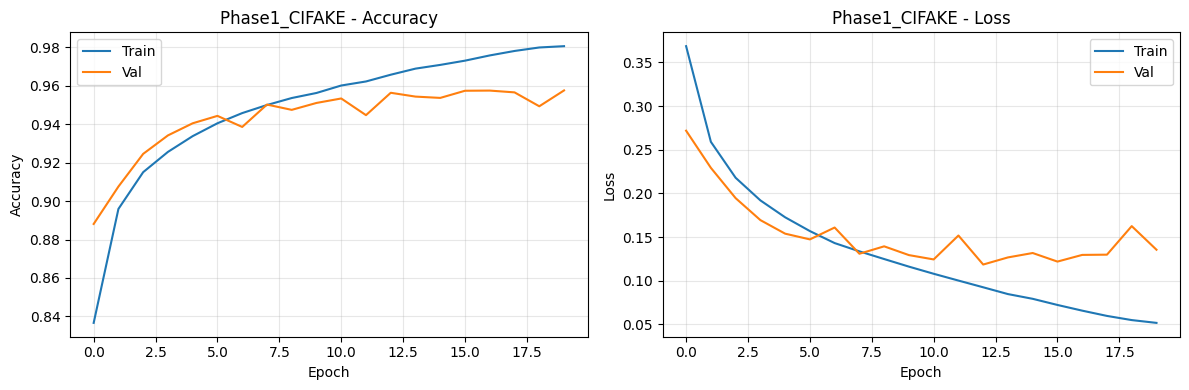

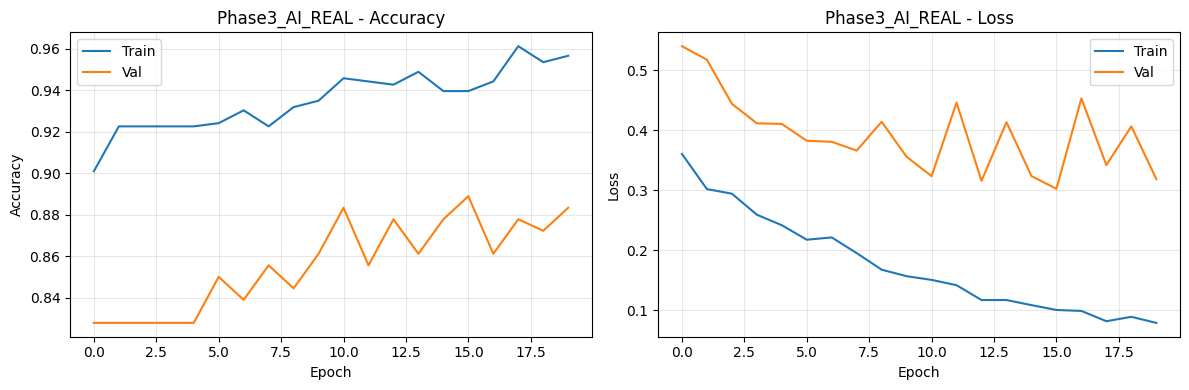

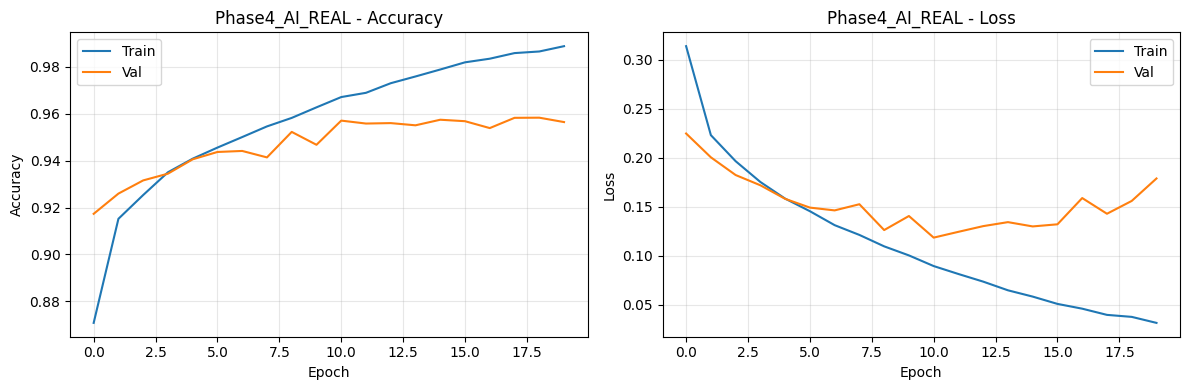

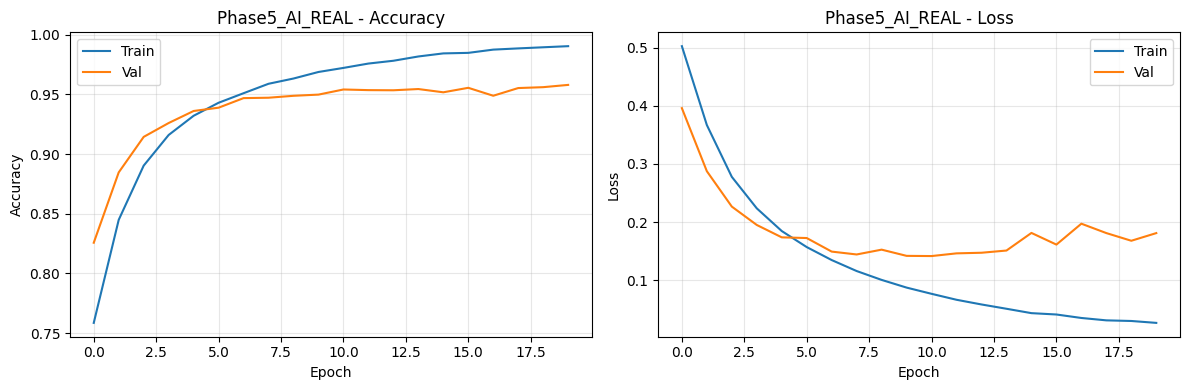

In [19]:
def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(history.history['accuracy'], label='Train')
    ax1.plot(history.history['val_accuracy'], label='Val')
    ax1.set_title(f'{title} - Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax2.plot(history.history['loss'], label='Train')
    ax2.plot(history.history['val_loss'], label='Val')
    ax2.set_title(f'{title} - Loss')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/{title}_history.png", dpi=100)
    plt.show()

plot_history(history_p1, 'Phase1_CIFAKE')
plot_history(history_p3, 'Phase3_AI_REAL')
plot_history(history_p4, 'Phase4_AI_REAL')
plot_history(history_p5, 'Phase5_AI_REAL')

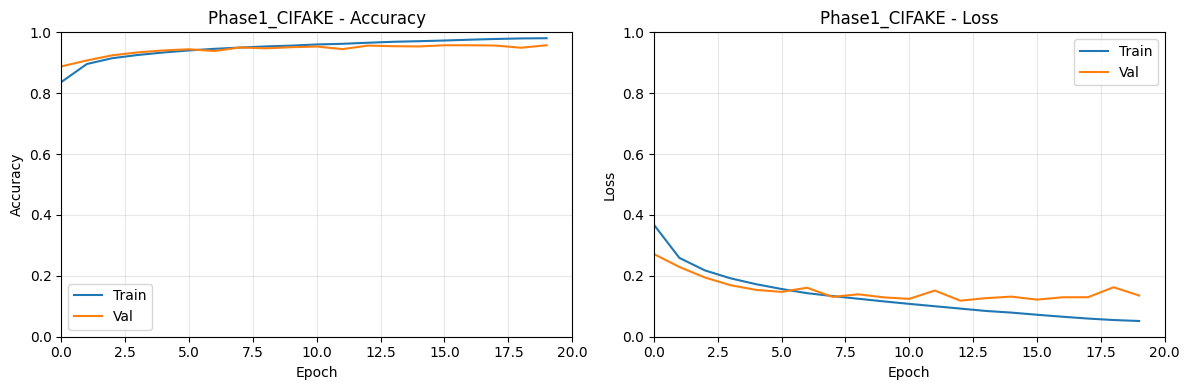

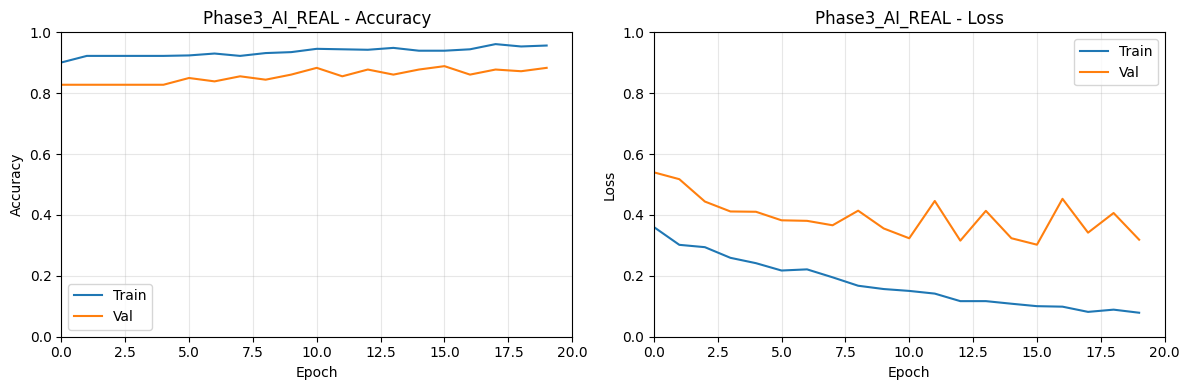

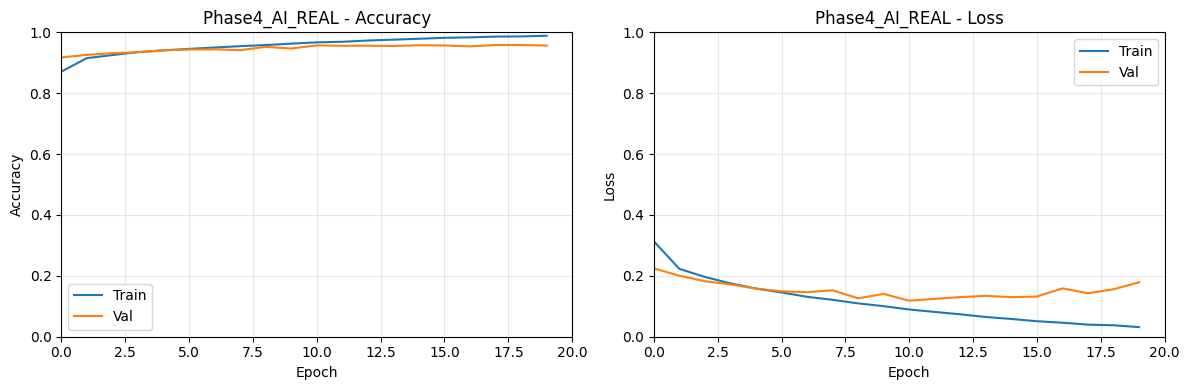

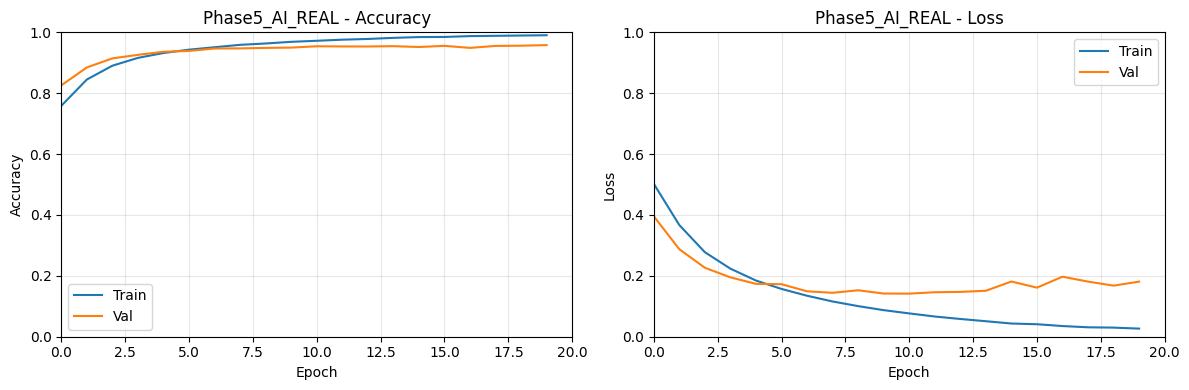

In [32]:
def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # Accuracy
    ax1.plot(history.history['accuracy'], label='Train')
    ax1.plot(history.history['val_accuracy'], label='Val')
    ax1.set_title(f'{title} - Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.set_xlim(0, 20)
    ax1.set_ylim(0, 1)
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Loss
    ax2.plot(history.history['loss'], label='Train')
    ax2.plot(history.history['val_loss'], label='Val')
    ax2.set_title(f'{title} - Loss')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.set_xlim(0, 20)
    ax2.set_ylim(0, 1)
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/{title}_history.png", dpi=100)
    plt.show()

plot_history(history_p1, 'Phase1_CIFAKE')
plot_history(history_p3, 'Phase3_AI_REAL')
plot_history(history_p4, 'Phase4_AI_REAL')
plot_history(history_p5, 'Phase5_AI_REAL')

## 4. 누적 학습 모델 평가

In [20]:
sequential_model = load_model("/content/drive/MyDrive/phase5.keras")

seq_loss, seq_acc = sequential_model.evaluate(test_ds)
print(f"누적 학습 모델 → test_acc: {seq_acc:.4f} / test_loss: {seq_loss:.4f}")

results_seq = {
    "dataset": "sequential_phase1_to_5",
    "test_acc": float(seq_acc),
    "test_loss": float(seq_loss)
}
with open(f"{SAVE_DIR}/results_sequential.json", "w") as f:
    json.dump(results_seq, f, indent=2)

563/563 ━━━━━━━━━━━━━━━━━━━━ 25s 44ms/step - accuracy: 0.7854 - loss: 1.1971
누적 학습 모델 → test_acc: 0.7854 / test_loss: 1.1971


In [45]:
from sklearn.metrics import f1_score
import numpy as np

test_ds_128 = load_test_ds(
    real_dir="/content/test_real/images",
    fake_dir="/content/test_fake/resized_data_Synthbuster/Synthbuster_Dataset",
    image_size=(128,128)
)

sequential_model = load_model("/content/drive/MyDrive/phase5.keras")

# 기존 평가
seq_loss, seq_acc = sequential_model.evaluate(test_ds_128)

# F1 계산
y_true = np.concatenate([y.numpy() for _, y in test_ds_128])

y_prob = sequential_model.predict(test_ds_128, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# AI=0, Real=1 이므로
seq_f1 = f1_score(y_true, y_pred, pos_label=0)

print(
    f"누적 학습 모델 → "
    f"test_acc: {seq_acc:.4f} / "
    f"test_loss: {seq_loss:.4f} / "
    f"f1: {seq_f1:.4f}"
)

results_seq = {
    "dataset": "sequential_phase1_to_5",
    "test_acc": float(seq_acc),
    "test_loss": float(seq_loss),
    "f1": float(seq_f1)
}

with open(f"{SAVE_DIR}/results_sequential.json", "w") as f:
    json.dump(results_seq, f, indent=2)

Real: 9000장, Fake: 9000장
563/563 ━━━━━━━━━━━━━━━━━━━━ 24s 40ms/step - accuracy: 0.7854 - loss: 1.1971
누적 학습 모델 → test_acc: 0.7854 / test_loss: 1.1971 / f1: 0.7561


### Catastrophic Forgetting 분석

Phase1: 0.4583
Phase3: 0.8000
Phase4: 0.4739
Phase5: 0.9100


/tmp/ipykernel_1268/2442397545.py:43: UserWarning: Glyph 45572 (\N{HANGUL SYLLABLE NU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1268/2442397545.py:43: UserWarning: Glyph 51201 (\N{HANGUL SYLLABLE JEOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1268/2442397545.py:43: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1268/2442397545.py:43: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1268/2442397545.py:43: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1268/2442397545.py:43: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1268/2442397545.py:43: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  plt.tight_la

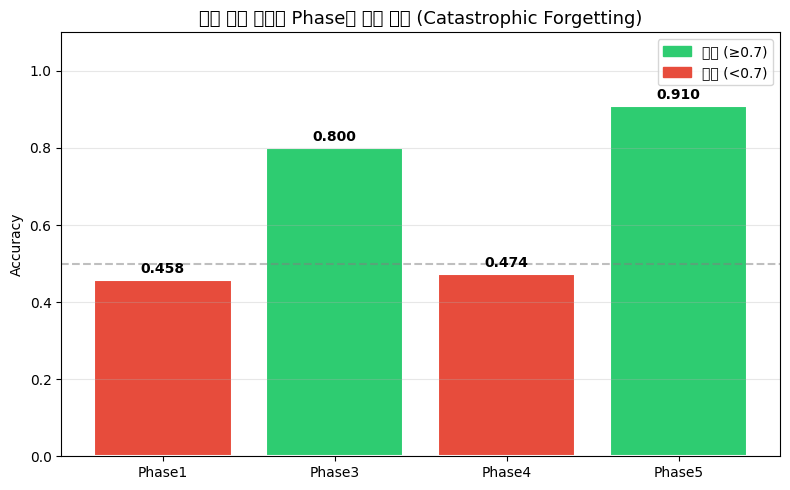

In [21]:
# 누적 학습 시 이전 phase 데이터를 얼마나 기억하는지 확인
cf_results = {}
for phase_name, phase_path in [
    ("Phase1", "/content/clean/Phase1_CIFAKE"),
    ("Phase3", "/content/clean/Phase3_AI_REAL"),
    ("Phase4", "/content/clean/Phase4_AI_REAL"),
    ("Phase5", "/content/clean/Phase5_AI_REAL"),
]:
    ai_paths = list(Path(f"{phase_path}/val/ai").glob("*.jpg")) + \
               list(Path(f"{phase_path}/val/ai").glob("*.png"))
    real_paths = list(Path(f"{phase_path}/val/real").glob("*.jpg")) + \
                 list(Path(f"{phase_path}/val/real").glob("*.png"))
    all_paths = [str(p) for p in ai_paths + real_paths]
    all_labels = [0] * len(ai_paths) + [1] * len(real_paths)
    def preprocess(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_image(img, channels=3, expand_animations=False)
        img = tf.image.resize(img, (128, 128))
        img = tf.cast(img, tf.float32)
        return img, label
    ds = tf.data.Dataset.from_tensor_slices((all_paths, all_labels))
    ds = ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE).batch(32).prefetch(tf.data.AUTOTUNE)
    loss, acc = sequential_model.evaluate(ds, verbose=0)
    cf_results[phase_name] = acc
    print(f"{phase_name}: {acc:.4f}")

# Catastrophic Forgetting 시각화
fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#e74c3c' if v < 0.7 else '#2ecc71' for v in cf_results.values()]
bars = ax.bar(cf_results.keys(), cf_results.values(), color=colors, edgecolor='white', linewidth=1.5)
ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Random baseline (0.5)')
for bar, val in zip(bars, cf_results.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.3f}', ha='center', va='bottom', fontweight='bold')
ax.set_title('누적 학습 모델의 Phase별 기억 성능 (Catastrophic Forgetting)', fontsize=13)
ax.set_ylabel('Accuracy')
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(True, axis='y', alpha=0.3)
good = mpatches.Patch(color='#2ecc71', label='정상 (≥0.7)')
bad = mpatches.Patch(color='#e74c3c', label='망각 (<0.7)')
ax.legend(handles=[good, bad])
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/catastrophic_forgetting.png", dpi=100)
plt.show()

## 5. 외부 모델 평가

In [ ]:
# 모델 구조에 따라 평가 방식이 달라질 수 있음
other_model_path = "/content/drive/MyDrive/other_model.keras"  # 경로 수정 필요

other_model = load_model(other_model_path)
other_loss, other_acc = other_model.evaluate(test_ds)
print(f"외부 모델 → test_acc: {other_acc:.4f} / test_loss: {other_loss:.4f}")

results_other = {
    "dataset": "other_model",
    "test_acc": float(other_acc),
    "test_loss": float(other_loss)
}
with open(f"{SAVE_DIR}/results_other.json", "w") as f:
    json.dump(results_other, f, indent=2)

In [51]:
# 누적 학습 ResNet18

file = "/content/drive/MyDrive/resnet18_cumulative_models/cumulative_resnet18_until_Phase5_AI_REAL.keras"

model_path = os.path.join(SAVE_DIR, file)
model = tf.keras.models.load_model(model_path)

input_size = model.input_shape[1]

test_ds = load_test_ds(
    real_dir="/content/test_real/images",
    fake_dir="/content/test_fake/resized_data_Synthbuster/Synthbuster_Dataset",
    image_size=(input_size, input_size)
)

loss, acc = model.evaluate(test_ds, verbose=1)

print(f"Loss: {loss:.4f}")
print(f"Accuracy: {acc:.4f}")

Real: 9000장, Fake: 9000장
563/563 ━━━━━━━━━━━━━━━━━━━━ 32s 52ms/step - accuracy: 0.8832 - loss: 0.3287
Loss: 0.3287
Accuracy: 0.8832


In [37]:
# 개별 학습 ResNet

SAVE_DIR = "/content/drive/MyDrive/resnet18_models"

model_files = [
    "resnet18_Phase1_CIFAKE.keras",
    "resnet18_Phase3_AI_REAL.keras",
    "resnet18_Phase4_AI_REAL.keras",
    "resnet18_Phase5_AI_REAL.keras"
]

results = []

for file in model_files:

    model_path = os.path.join(SAVE_DIR, file)

    print("=" * 60)
    print("Evaluating:", file)
    print("=" * 60)

    model = tf.keras.models.load_model(model_path)

    # 모델 입력 크기 자동 확인
    input_size = model.input_shape[1]

    # 테스트셋 생성
    test_ds = load_test_ds(
        real_dir="/content/test_real/images",
        fake_dir="/content/test_fake/resized_data_Synthbuster/Synthbuster_Dataset",
        image_size=(input_size, input_size)
    )

    loss, acc = model.evaluate(test_ds, verbose=1)

    results.append({
        "model": file,
        "input_size": input_size,
        "loss": loss,
        "accuracy": acc
    })

result_df = pd.DataFrame(results)
result_df = result_df.sort_values(
    by="accuracy",
    ascending=False
)

result_df

Evaluating: resnet18_Phase1_CIFAKE.keras
Real: 9000장, Fake: 9000장
563/563 ━━━━━━━━━━━━━━━━━━━━ 32s 53ms/step - accuracy: 0.1884 - loss: 11.8938
Evaluating: resnet18_Phase3_AI_REAL.keras
Real: 9000장, Fake: 9000장
563/563 ━━━━━━━━━━━━━━━━━━━━ 31s 51ms/step - accuracy: 0.5000 - loss: 1.1690
Evaluating: resnet18_Phase4_AI_REAL.keras
Real: 9000장, Fake: 9000장
563/563 ━━━━━━━━━━━━━━━━━━━━ 31s 52ms/step - accuracy: 0.4408 - loss: 4.2131
Evaluating: resnet18_Phase5_AI_REAL.keras
Real: 9000장, Fake: 9000장
563/563 ━━━━━━━━━━━━━━━━━━━━ 31s 52ms/step - accuracy: 0.8756 - loss: 0.3323


,model,input_size,loss,accuracy
3,resnet18_Phase5_AI_REAL.keras,224,0.332260,0.875556
1,resnet18_Phase3_AI_REAL.keras,224,1.169009,0.500000
2,resnet18_Phase4_AI_REAL.keras,224,4.213066,0.440778
0,resnet18_Phase1_CIFAKE.keras,224,11.893752,0.188389


## 6. 전체 모델 비교 시각화

In [22]:
# 각 결과 파일에서 test_acc 불러오기
def load_results(filename):
    path = f"{SAVE_DIR}/{filename}"
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return None

all_results = {}
for name, fname in [
    ("Phase1\n(CIFAKE)", "results_phase1.json"),
    ("Phase3\n(AI vs Real)", "results_phase3.json"),
    ("Phase4\n(AI vs Human)", "results_phase4.json"),
    ("Phase5\n(Faces)", "results_phase5.json"),
    ("누적\n학습", "results_sequential.json"),
    #("외부\n모델", "results_other.json"),
]:
    r = load_results(fname)
    if r:
        all_results[name] = r["test_acc"]

print("수집된 결과:")
for name, acc in all_results.items():
    print(f"  {name.replace(chr(10), ' ')}: {acc:.4f}")

수집된 결과:
  Phase1 (CIFAKE): 0.2019
  Phase3 (AI vs Real): 0.4824
  Phase4 (AI vs Human): 0.4848
  Phase5 (Faces): 0.7910
  누적 학습: 0.7854


/tmp/ipykernel_1268/1750448968.py:25: UserWarning: Glyph 45572 (\N{HANGUL SYLLABLE NU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1268/1750448968.py:25: UserWarning: Glyph 51201 (\N{HANGUL SYLLABLE JEOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1268/1750448968.py:25: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1268/1750448968.py:25: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1268/1750448968.py:26: UserWarning: Glyph 45572 (\N{HANGUL SYLLABLE NU}) missing from font(s) DejaVu Sans.
  plt.savefig(f"{SAVE_DIR}/model_comparison.png", dpi=150)
/tmp/ipykernel_1268/1750448968.py:26: UserWarning: Glyph 51201 (\N{HANGUL SYLLABLE JEOG}) missing from font(s) DejaVu Sans.
  plt.savefig(f"{SAVE_DIR}/model_comparison.png", dpi=150)
/tmp/ipykernel_1268/1750448968.py:26: UserWarning: Glyph 54

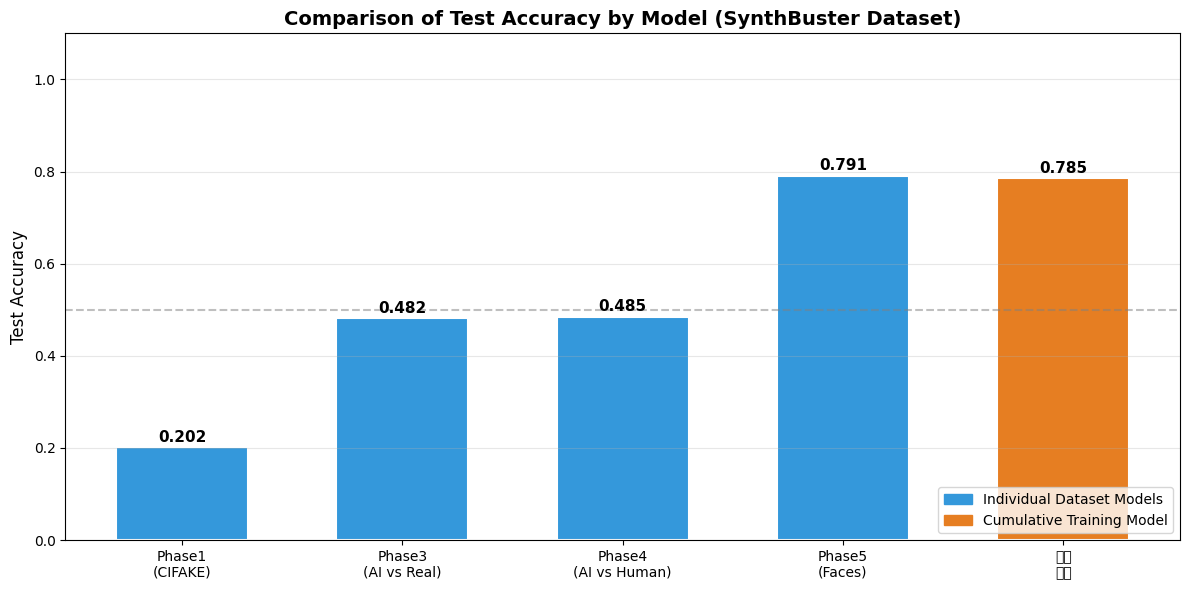

In [53]:
# Model-wise test accuracy comparison bar chart
fig, ax = plt.subplots(figsize=(12, 6))

colors = ['#3498db', '#3498db', '#3498db', '#3498db', '#e67e22', '#9b59b6']
bars = ax.bar(all_results.keys(), all_results.values(),
              color=colors[:len(all_results)], edgecolor='white', linewidth=1.5, width=0.6)

ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Random baseline')

for bar, val in zip(bars, all_results.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{val:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title('Comparison of Test Accuracy by Model (SynthBuster Dataset)', fontsize=14, fontweight='bold')
ax.set_ylabel('Test Accuracy', fontsize=12)
ax.set_ylim(0, 1.1)
ax.grid(True, axis='y', alpha=0.3)

ind = mpatches.Patch(color='#3498db', label='Individual Dataset Models')
seq = mpatches.Patch(color='#e67e22', label='Cumulative Training Model')
#oth = mpatches.Patch(color='#9b59b6', label='External Models')

ax.legend(handles=[ind, seq], loc='lower right')

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/model_comparison.png", dpi=150)
plt.show()

In [26]:
# 최종 결과 요약 테이블 출력
print("\n" + "="*55)
print(f"{'모델':<20} {'Test Accuracy':>15} {'순위':>8}")
print("="*55)
sorted_results = sorted(all_results.items(), key=lambda x: x[1], reverse=True)
for rank, (name, acc) in enumerate(sorted_results, 1):
    print(f"{name.replace(chr(10), ' '):<20} {acc:>15.4f} {rank:>8}")
print("="*55)
print(f"테스트 데이터: SynthBuster (Real 9,000장 / AI 9,000장)")
print(f"AI 생성 모델: DALL·E 2/3, Midjourney v5, SD 등 9종")


모델                     Test Accuracy       순위
Phase5 (Faces)                0.7910        1
누적 학습                         0.7854        2
Phase4 (AI vs Human)          0.4848        3
Phase3 (AI vs Real)           0.4824        4
Phase1 (CIFAKE)               0.2019        5
테스트 데이터: SynthBuster (Real 9,000장 / AI 9,000장)
AI 생성 모델: DALL·E 2/3, Midjourney v5, SD 등 9종
